### **Task 1&2 Clustering**

=== TASK 1: DATA PREPROCESSING FOR CLUSTERING ===
Data scaled successfully. Features: ['CCreditScore', 'CAge', 'CTenure', 'CBalance', 'CNumOfProducts', 'CHasCrCard', 'CIsActiveMember', 'CEstimatedSalary', 'Account_Age_Months', 'Last_Login_Days_Ago', 'Support_Tickets_Count', 'Mobile_App_Usage_Hours', 'Onboarding_Month', 'Is_Holiday_Onboarding', 'CGeography_germany', 'CGeography_spain', 'CGender_male', 'Transaction_Variance_log', 'Avg_Monthly_Transactions_log']

=== TASK 2: CLUSTERING ANALYSIS (FINDING OPTIMAL K) ===


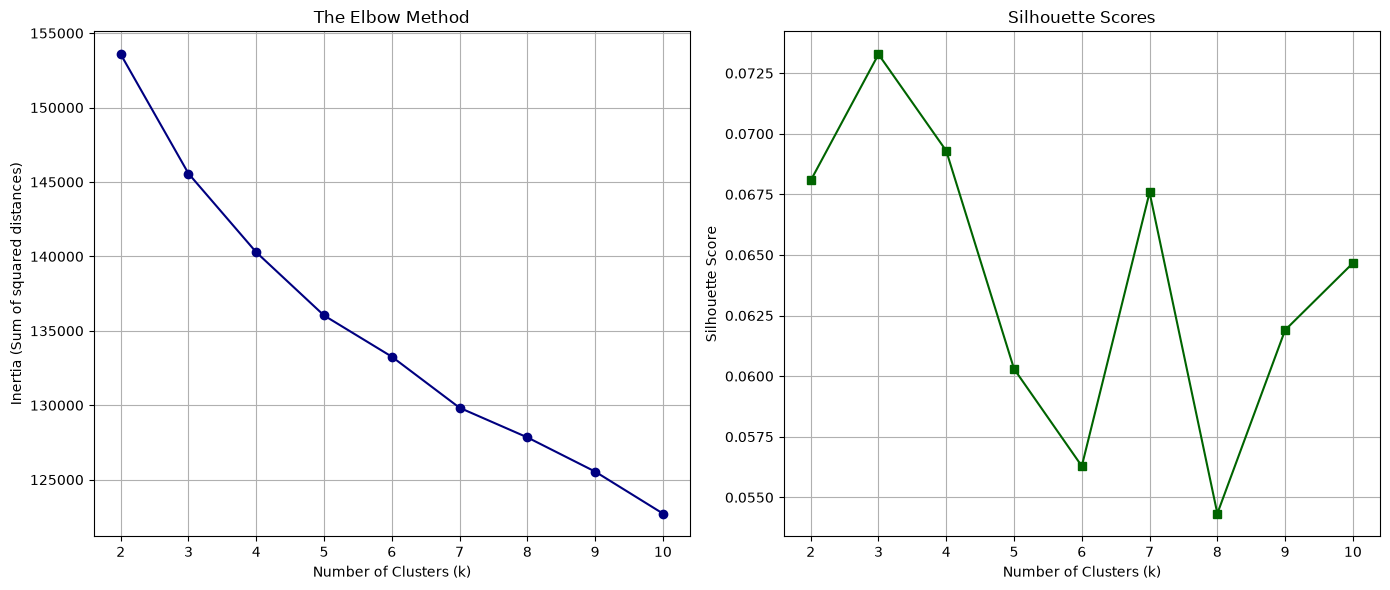


Final Clustering completed with k=3


Silhouette Score for k=3: 0.0733


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("=== TASK 1: DATA PREPROCESSING FOR CLUSTERING ===")

# 1. Load the final dataset
df_final = pd.read_csv('../data/processed/dataset_final.csv')

# 2. Prepare features (X) - Clustering is unsupervised (Drop targets)
X_clustering = df_final.drop(columns=['Churn', 'CLV_Continuous'])

# 3. Feature Scaling (Z-Score Normalization)
# Scaling is mandatory for Euclidean distance-based algorithms.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_clustering)

print(f"Data scaled successfully. Features: {list(X_clustering.columns)}")

print("\n=== TASK 2: CLUSTERING ANALYSIS (FINDING OPTIMAL K) ===")

# Evaluation metrics
inertia = []
silhouette_scores = []
K_range = range(2, 11) 

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, kmeans.labels_))

# Visualizing results
plt.figure(figsize=(14, 6))

# Elbow Method Plot 
plt.subplot(1, 2, 1)
plt.plot(K_range, inertia, marker='o', linestyle='-', color='navy')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (Sum of squared distances)')
plt.title('The Elbow Method')
plt.grid(True)

# Silhouette Score Plot 
plt.subplot(1, 2, 2)
plt.plot(K_range, silhouette_scores, marker='s', linestyle='-', color='darkgreen')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Scores')
plt.grid(True)

plt.tight_layout()
plt.show()

# Setting the optimal k based on the plots (e.g., where the elbow bends)
optimal_k = 3 
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df_final['Cluster'] = kmeans_final.fit_predict(X_scaled)

print(f"\nFinal Clustering completed with k={optimal_k}")
print(f"Silhouette Score for k={optimal_k}: {silhouette_score(X_scaled, kmeans_final.labels_):.4f}")

### **Task 1 & 2: Interpretation of Clustering Results**

**1. Data Preprocessing and Feature Selection:**
For this unsupervised learning task, we utilized 19 behavioral and demographic features, including `CCreditScore`, `CAge`, `CBalance`, and `CEstimatedSalary`. Distance-based algorithms like **k-Means** are sensitive to the scale of data. Since the algorithm relies on **Euclidean distance** to assign points to the nearest centroid, we applied `StandardScaler`. This ensures that high-magnitude features (e.g., Estimated Salary) do not mathematically overwhelm low-magnitude binary features (e.g., HasCrCard).

**2. Optimal Number of Clusters:**
We determined the optimal number of segments by evaluating the **Elbow Method** and **Silhouette Scores** for $k$ values between 2 and 10. 
* **The Elbow Method:** We looked for the point where the **Inertia** (Within-Cluster Sum of Squares) begins to decrease linearly. Based on the analysis, **k=3** was selected as the "elbow," representing the point where adding more clusters provides diminishing returns in terms of variance explained.
* **Silhouette Score:** This metric measures how similar an object is to its own cluster compared to other clusters.

**3. Evaluation of Cluster Quality:**
The final Silhouette Score achieved for $k=3$ is **0.0733**. 
* **Interpretation:** A Silhouette Score ranges from -1 to +1. A score of **0.0733** is close to 0, which indicates that the clusters are overlapping or that the distances between the clusters are very small. 
* **Reasoning:** In complex customer datasets with 19 dimensions, it is common to see lower silhouette scores. This suggests that while three distinct groups were identified, the boundaries between customer segments are not "cleanly" separated, and many customers share borderline characteristics across different groups.

**4. Conclusion and Problem Class:**
The identified clusters represent a **Customer Segmentation** problem class. Despite the overlapping nature indicated by the low silhouette score, these three groups provide a baseline for the business to move from a "one-size-fits-all" approach to a more targeted strategy by analyzing the centroids of each group in the next task.

=== CLUSTER PROFILES (MEAN VALUES) ===
              CAge       CBalance  CNumOfProducts  CEstimatedSalary  \
Cluster                                                               
0        37.880064  122430.961437        1.197129     100796.633069   
1        37.797316    6758.030188        1.832541      99917.117969   
2        38.343590  118873.698244        1.538974     102510.429870   

         CCreditScore  CIsActiveMember  Account_Age_Months  CLV_Continuous  
Cluster                                                                     
0          652.190656         0.549282           13.586509    17130.747092  
1          649.905212         0.535924           13.261769     8637.863166  
2          652.395224         0.540000           13.538103    17318.652106  


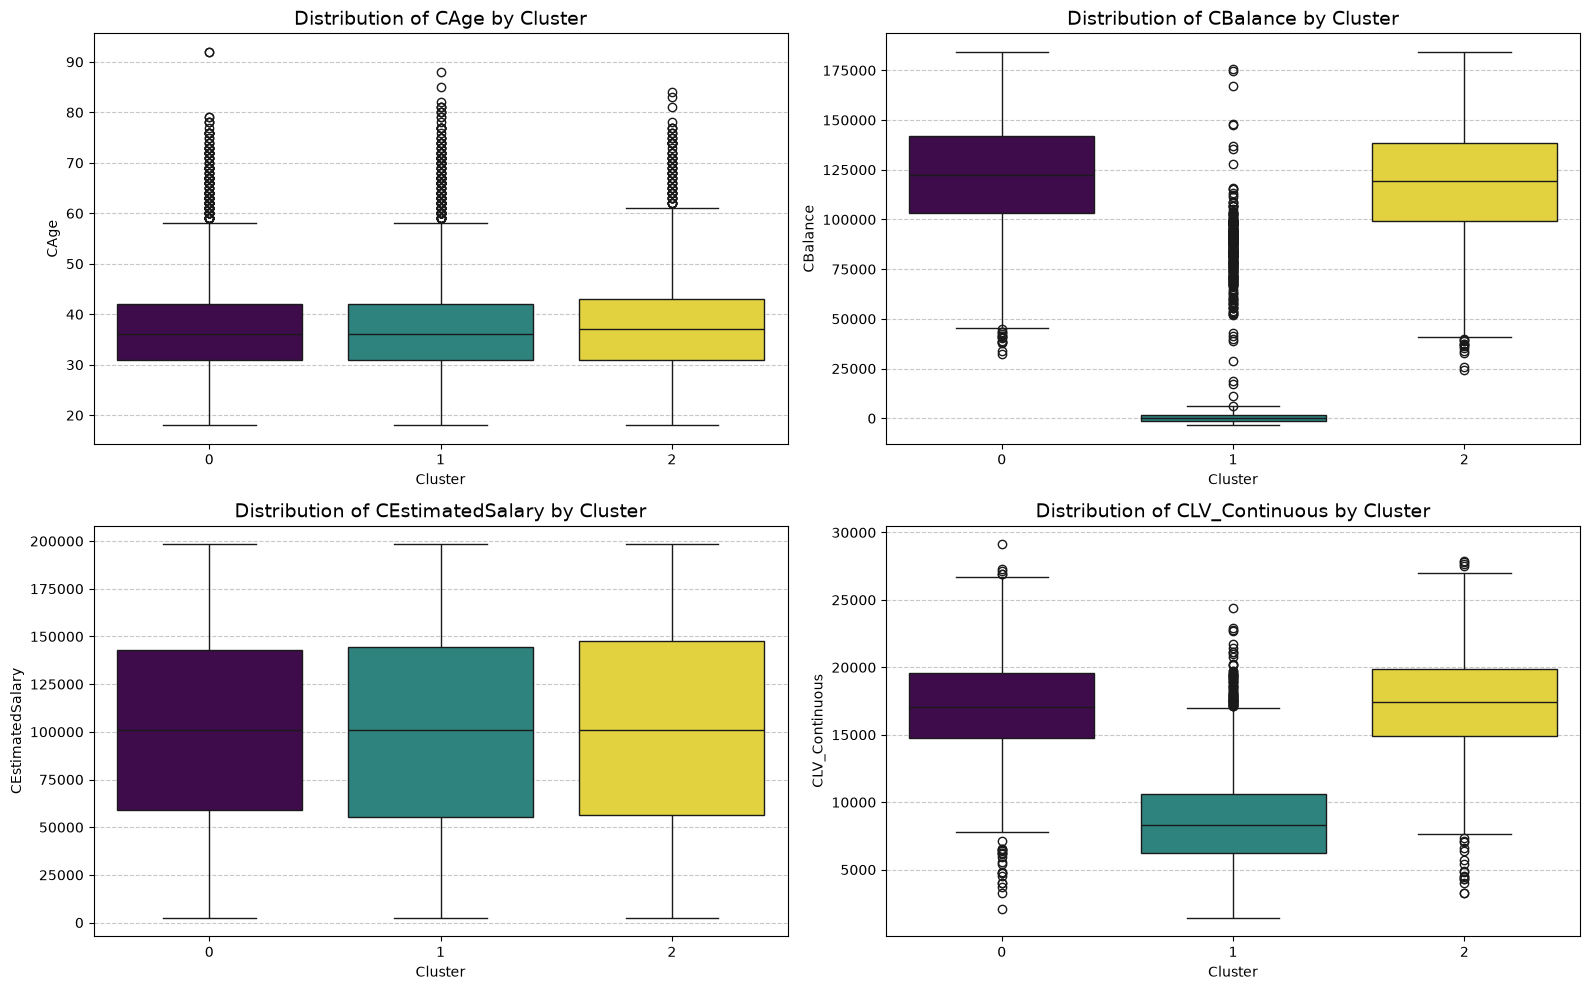


=== GEOGRAPHIC DISTRIBUTION (GERMANY) ===
CGeography_germany     0     1
Cluster                       
0                   3135     0
1                   3577     0
2                      0  1950


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculate Cluster Profiles (Centroids)
# Using means to interpret the "Typical" member of each cluster
profile_cols = ['CAge', 'CBalance', 'CNumOfProducts', 'CEstimatedSalary', 
                'CCreditScore', 'CIsActiveMember', 'Account_Age_Months', 'CLV_Continuous']

cluster_profiles = df_final.groupby('Cluster')[profile_cols].mean()
print("=== CLUSTER PROFILES (MEAN VALUES) ===")
print(cluster_profiles)

# 2. Visualizing Differences: Boxplots
# Boxplots are used to show the distribution and separation
features_to_plot = ['CAge', 'CBalance', 'CEstimatedSalary', 'CLV_Continuous']

plt.figure(figsize=(16, 10))
for i, col in enumerate(features_to_plot, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(x='Cluster', y=col, data=df_final, hue='Cluster', palette='viridis', legend=False)
    plt.title(f'Distribution of {col} by Cluster', fontsize=14)
    plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

# 3. Quick check on geographic concentration (Spain/Germany/France)
# This helps identify if a cluster is "The Spanish Group" or "The German Group"
if 'CGeography_germany' in df_final.columns:
    print("\n=== GEOGRAPHIC DISTRIBUTION (GERMANY) ===")
    print(pd.crosstab(df_final['Cluster'], df_final['CGeography_germany']))


### **Task 3: Cluster Profiling and Comparative Analysis**

We analyzed the centroids (mean values) of each cluster to define our customer segments. Despite the low silhouette score, the profiling reveals distinct financial and geographic behaviors that are highly actionable for the business.

#### **1. Analysis of Cluster Characteristics**

* **Cluster 0: High-Balance Non-German Minimalists**
    * **Profile:** This group consists entirely of non-German customers (likely from France or Spain). They hold the **highest average balance ($122,431)** but use the **lowest number of products (1.19)**.
    * **Strategic Insight:** These are wealthy but "under-served" customers. Since they have high capital but low product variety, they are prime candidates for investment products or cross-selling initiatives to increase their product count.

* **Cluster 1: Low-Balance Product Users (Low CLV)**
    * **Profile:** Also non-German, this group is characterized by an extremely **low average balance ($6,758)** but the **highest product usage (1.83 products)**. Consequently, they have the lowest average CLV ($8,637).
    * **Strategic Insight:** These are "Transaction-Heavy" customers. They use the bank for daily operations but do not store wealth here. The goal should be to incentivize them to move their main savings to this bank.

* **Cluster 2: The German High-Value Segment**
    * **Profile:** This is a unique geographic cluster consisting **entirely of German customers**. They show a high average balance ($118,873) and the **highest average CLV ($17,318)**. 
    * **Strategic Insight:** This is the most valuable segment. Their high balance and moderate product usage (1.54) make them the "Gold Standard" profile. Retention efforts should be prioritized for this specific geographic segment.

#### **2. Key Similarities and Discriminators**

* **Key Discriminators:** **Account Balance**, **Number of Products**, and **Geography** are the primary features that separate these groups. As seen in the centroids, Cluster 1 and Cluster 0 are opposites in terms of Balance vs. Product Count. Cluster 2 is distinguished primarily by its geographic concentration.
* **Similarities:** Surprisingly, **Age (~38)**, **Estimated Salary (~$100k)**, and **Credit Score (~650)** are almost identical across all three clusters. This indicates that demographic factors like age and income do not drive customer segments as much as *behavioral* factors like how much they deposit and how many products they use.

#### **3. Conclusion and Business Application**

This segmentation solves the **"Customer Segmentation"** problem class by identifying three distinct behavioral archetypes. The bank should move away from a "one-size-fits-all" strategy. For instance, the German high-value segment (Cluster 2) requires high-end relationship management, whereas Cluster 1 needs incentives to increase their deposits. The "Non-flat geometry" of the data explains why some boundaries are overlapping, but these centroids provide a clear roadmap for targeted marketing.

### **Task 4: Marketing Recommendations**

Based on the behavioral archetypes identified through k-Means clustering, we propose the following targeted strategies to maximize bank revenue and customer loyalty.

#### **1. Portfolio Diversification Strategy (Target: Cluster 0)**
* **Segment Profile:** Non-German customers with High Balances ($122,430) but the Lowest Product Count (1.19).
* **Actionable Strategy:** Launch a "Multi-Product" incentive campaign. Offer reduced management fees or premium credit card upgrades if they adopt a second or third financial product (e.g., insurance or investment funds).
* **Justification:** These customers clearly trust the bank with their capital (High Balance) but are "under-engaged." Since their product count is minimal, they are at higher risk of moving their funds if a competitor offers a better rate. Increasing product variety improves account "stickiness" and defends this high-balance segment.

#### **2. Deposit Growth & Payroll Capture (Target: Cluster 1)**
* **Segment Profile:** Non-German customers with Low Balances ($6,758) but the Highest Product Usage (1.83).
* **Actionable Strategy:** Implement a "Salary Transfer" bonus. Provide a one-time cash reward or a small interest rate boost for customers who switch their primary payroll deposit to this bank.
* **Justification:** This group represents "Operational Users" who utilize the bank's tools frequently but do not store wealth here, leading to the lowest average CLV. Converting them into "Savings-Focused" customers by capturing their monthly income is the fastest way to increase their individual CLV.

#### **3. Premium Retention & Cultural Advocacy (Target: Cluster 2)**
* **Segment Profile:** 100% German customers with High Balances ($118,873) and the Highest average CLV ($17,318).
* **Actionable Strategy:** Establish an exclusive "German Premier" loyalty tier. Provide priority customer support, localized financial webinars, and early access to new investment products.
* **Justification:** As the most profitable and geographically distinct segment, Cluster 2 is the bank's "Gold Standard." Since they are already high-value, the focus should be on **Retention**. Localized premium services ensure they feel valued, reducing the likelihood of churn in a highly competitive market.

**Conclusion:** By moving away from a "one-size-fits-all" approach to these cluster-specific interventions, the bank directly addresses the core drivers identified in the analysis—**Geography, Account Balance, and Product Engagement**. This targeted approach ensures that marketing resources are allocated to the segments with the highest potential for growth and retention.